<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetection_Keerthna2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HQ-IDS, a hybrid variational quantum circuit for intrusion detection: Keerthna et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Keerthna M. P., C. M. Nalayini, Jenifer Shylaja M. and Stephan J., "Quantum-Enhanced Network Intrusion Detection using
> Variational Quantum Machine Learning", *2026 International Conference on Trends in Quantum Computing and Emerging Business
> Technologies (TQCEBT)*, Pune, India, April 9-11, 2026, IEEE. DOI 10.1109/TQCEBT67648.2026.11681255

The paper publishes no code. Everything below is written from its four-page description, with the software stack it names:
PennyLane (`default.qubit` simulator, automatic differentiation) for the quantum part, scikit-learn for standardisation and PCA.

**What the notebook does.** It downloads the public NSL-KDD intrusion dataset (the paper used a *synthetic* "generated network
traffic data set" that it does not publish, so a real public dataset of the same kind stands in, see the table below), applies
the paper's preprocessing (standardisation, PCA to 4 components, Min-Max scaling, arctan normalisation, all fitted on the
training split only), builds the paper's 4-qubit circuit (one `RY` angle encoding per qubit, three layers of `RX`-`RY`-`RZ` +
`CNOT` entanglers, a Pauli-Z expectation value per qubit, a classical linear read-out with a sigmoid) and trains it with the
paper's recipe (binary cross-entropy, Adam with learning rate 0.1, 60 epochs, batch size 24, gradients by automatic
differentiation). A random forest, an RBF-kernel SVM, a logistic regression and a small neural network are trained on exactly
the same 4 numbers per connection, and a forest and an SVM on all 41 features. The paper's figures (training curve, confusion
matrix, classical-versus-quantum comparison) are redrawn, a depolarising-noise sweep tests the "NISQ-ready" claim, and the last
section puts the paper's numbers (training accuracy 92.53 %, test accuracy 90.83 %) next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a
pinned PennyLane; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account and no
Hugging Face token are needed (NSL-KDD is a public GitHub mirror).

**Runtime.** `FAST_MODE = True` (600 connections, 15 epochs, one seed) takes a few minutes on a laptop CPU.
`FAST_MODE = False` uses the paper's budgets (60 epochs, batch 24, learning rate 0.1) on 1,200 connections and three seeds plus
the preprocessing ablations; the committed notebook states in its first output cell which of the two it contains.

**What you get at the end.** A trained 41-parameter hybrid model, its learning curve and confusion matrix, a table of classical
baselines on identical inputs, a noise sweep, and a claim-by-claim comparison with the paper.

## The paper in one page

**Problem.** Decide for each network connection whether it is normal or malicious (binary label, 0 = normal, 1 = attack).

**Method (Fig. 1 of the paper, five stages).**
1. *Preprocessing.* Standardise every feature (zero mean, unit variance), then PCA down to as many features as qubits.
2. *Feature encoding.* Normalise with an arctan function and encode each of the $Q$ values as a rotation angle:
   $\theta_i = \arctan(z_i)$, $U_{enc} = \bigotimes_{i=1}^{Q} R_Y(\theta_i)$.
3. *Variational circuit.* $L$ stacked layers; in each layer every qubit gets trainable $R_X, R_Y, R_Z$ rotations and then an
   entangling block of CNOT gates $U_{ent}$.
4. *Measurement.* The Pauli-Z expectation value $z_i = \langle\psi|Z_i|\psi\rangle$ of every qubit, a fixed-size quantum feature vector.
5. *Classical read-out.* $\hat y = \sigma(\sum_i w_i z_i + b)$ (logistic regression on the quantum features), binary cross-entropy
   loss, gradients by automatic differentiation for both the quantum and the classical parameters.

**Setup (Section IV).** 4 qubits taken from the PCA-reduced features, PennyLane `default.qubit`, 3 variational layers of
RX, RY, RZ and CNOT gates, standardisation + PCA + Min-Max scaling + arctan normalisation, Adam with learning rate 0.1,
60 epochs, batch size 24.

**Data.** "Generated network traffic data set" (synthetic). No size, features, class balance or split is given.

**Claims.**

| Claim | Where | Value |
|---|---|---|
| Training accuracy after 60 epochs | Section IV, IV.A, Fig. 2 | 92.53 % |
| Test accuracy | Section IV, IV.A, Fig. 2 | 90.83 % |
| Training accuracy "increased rapidly in the first epochs" and then converged | Section IV | qualitative |
| Confusion matrix: most normal and attack connections correct, few errors | Fig. 2 | qualitative (no counts in the text) |
| The model generalises to unseen data | IV.A | qualitative |
| Competitive with classical ML-based IDS; better accuracy, "enhanced noise tolerance", equal scalability | IV.B, Fig. 3 | qualitative bar chart, no numbers |
| Scalable to NISQ devices | abstract, Section V | qualitative |

The numbers 0.9083 and 0.9253 are the only checkable quantitative statements. Fig. 3 compares against a classical RNN-LSTM/ANN
IDS taken from a different paper (reference [10]) and gives no values.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | synthetic generated traffic, not published | **NSL-KDD `KDDTrain+` (125,973 real connections), binary normal / attack.** A real public dataset of the same kind replaces the unpublished synthetic data; accuracies are therefore not directly comparable |
| Sample size and split | not stated | `# CHOICE:` 1,200 connections drawn class-balanced (600 normal + 600 attack), stratified 70 : 30 (840 train / 360 test). 0.9083 = 327/360, so a 360-row test split is consistent with the reported figure |
| Qubits / PCA components | 4 | 4 |
| Standardisation, PCA | yes, fitted on training data | `StandardScaler` -> `PCA(4)`, training split only |
| Min-Max scaling and arctan | both listed (Section IV), order and ranges not stated | `# CHOICE:` literal order: `MinMaxScaler((0, 1))` fitted on the training PCA scores (test clipped), then `arctan`; two alternative readings are run as an ablation |
| Encoding | $R_Y(\theta_i)$ per qubit | same |
| Variational layers | 3 layers of RX, RY, RZ + CNOT | 3 layers, each: RX, RY, RZ on every qubit, then CNOTs |
| CNOT topology | not stated | `# CHOICE:` ring: CNOT(0,1), (1,2), (2,3), (3,0) after every layer |
| Measurement | $\langle Z_i\rangle$ per qubit | same, exact expectation values (no shot noise), as on `default.qubit` |
| Read-out | linear layer + sigmoid | $\sigma(w\cdot z + b)$ with $w\in\mathbb{R}^4$, 5 classical parameters |
| Loss, optimiser | BCE, Adam, lr 0.1 | same (`qml.AdamOptimizer(0.1)`); gradients by backprop through `default.qubit` |
| Epochs, batch size | 60, 24 | 60, 24 (FAST_MODE shortens the epochs) |
| Parameter initialisation | not stated | `# CHOICE:` rotation angles uniform on $[0, 2\pi)$, read-out weights $N(0, 0.1^2)$, bias 0 |
| Random seeds | not stated | 42 (and 43, 44 in the full run) |
| "Training accuracy" | not defined | `# CHOICE:` accuracy of the final model on the whole training split (not a running average over mini-batches) |
| Classical baselines | one classical IDS in Fig. 3 (from another paper), no numbers | RF, RBF-SVM, logistic regression, small MLP on the same 4 inputs; RF and SVM on all 41 features |
| Noise tolerance | Fig. 3, qualitative | `# CHOICE:` depolarising channel after every gate, swept from 0 to 3 % |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False           # True: class demo (600 connections, 15 epochs, 1 seed). False: the paper's budgets, 1,200 connections, 3 seeds.
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # unused: the paper simulates on PennyLane default.qubit; kept for uniformity with the other notebooks

# --- the paper's architecture and training recipe (Section IV) ---
N_QUBITS  = 4               # paper: 4 qubits = 4 PCA components
N_LAYERS  = 3               # paper: three variational layers
LR        = 0.1             # paper: Adam, learning rate 0.1
BATCH     = 24              # paper: batch size 24
EPOCHS_PAPER = 60           # paper: 60 epochs

# --- choices the paper leaves open ---
TEST_SIZE = 0.30            # CHOICE: stratified 70 : 30 split
PRIMARY_VARIANT = "minmax01_arctan"   # CHOICE: literal reading of Section IV (standardise -> PCA -> Min-Max -> arctan)
ABLATION_VARIANTS = ["zscore_arctan", "minmax_pi"]   # other readings of the angle normalisation, run on SEED only
NOISE_LEVELS = [0.0, 0.001, 0.003, 0.01, 0.03]       # CHOICE: depolarising probability after every gate
N_NOISE_EVAL = 120          # test connections used for the (slow) mixed-state noise sweep

if FAST_MODE:
    N_SAMPLES = 600         # connections (half normal, half attack)
    EPOCHS    = 15
    SEEDS     = [SEED]
    RUN_ABLATION = False
else:
    N_SAMPLES = 1200        # CHOICE: 600 + 600, 840 train / 360 test
    EPOCHS    = EPOCHS_PAPER
    SEEDS     = [SEED, SEED + 1, SEED + 2]
    RUN_ABLATION = True

DATA_DIR = "data"
NSL_KDD_URLS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"]
print("FAST_MODE =", FAST_MODE, "| connections:", N_SAMPLES, "| epochs:", EPOCHS, "(paper:", EPOCHS_PAPER, ") | seeds:", SEEDS,
      "| ablation:", RUN_ABLATION)

FAST_MODE = False | connections: 1200 | epochs: 60 (paper: 60 ) | seeds: [42, 43, 44] | ablation: True


In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

import pennylane as qml
from pennylane import numpy as pnp

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pnp.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. The NSL-KDD dataset

The paper evaluated on a synthetic "generated network traffic data set" and does not publish the generator, the number of
connections or the features. Making up our own synthetic data would only reproduce our own generator, so the notebook uses the
closest *real* public dataset of the same kind: **NSL-KDD** (Tavallaee et al., 2009), the cleaned-up KDD Cup 1999 data. Every
row is one TCP/UDP/ICMP connection described by 41 features (duration, protocol, service, bytes in each direction, login flags,
error rates over the last 100 connections, ...), a label naming the attack type or `normal`, and a difficulty score. The
file `KDDTrain+` holds 125,973 connections. The 38 attack names are grouped into the four standard families (DoS, Probe, R2L,
U2R) so that plots can be coloured by attack family, while the model itself is **binary** (normal against any attack), as in the
paper. The file is 19 MB and is cached in `DATA_DIR`.

In [4]:
COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
CAT_COLS = ["protocol_type", "service", "flag"]
FEATURE_COLS = [c for c in COLUMNS if c not in ("label", "difficulty")]
FAMILIES = ["normal", "DoS", "Probe", "R2L", "U2R"]

ATTACK_FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    ATTACK_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    ATTACK_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    ATTACK_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    ATTACK_FAMILY[a] = "U2R"

def fetch_nsl_kdd():
    path = os.path.join(DATA_DIR, "KDDTrain+.txt")
    if not os.path.exists(path):
        import requests
        for url in NSL_KDD_URLS:
            try:
                r = requests.get(url, timeout=180); r.raise_for_status()
                open(path, "wb").write(r.content); print("downloaded KDDTrain+.txt from", url.split("/")[3]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        else:
            raise RuntimeError("could not download KDDTrain+.txt; put it into DATA_DIR by hand")
    else:
        print("using cached", path)
    return pd.read_csv(path, header=None, names=COLUMNS)

t0 = time.time()
raw = fetch_nsl_kdd()
raw["family"] = raw["label"].map(ATTACK_FAMILY)
assert raw["family"].notna().all(), "unmapped attack names: %s" % sorted(set(raw.loc[raw["family"].isna(), "label"]))
raw["is_attack"] = (raw["family"] != "normal").astype(int)         # binary target of the paper: 0 normal, 1 attack
print(f"loaded in {time.time()-t0:.1f} s: {len(raw):,} connections x {len(FEATURE_COLS)} features")
print("missing values:", int(raw[FEATURE_COLS].isna().sum().sum()), "| infinities:",
      int(np.isinf(raw[FEATURE_COLS].select_dtypes("number")).sum().sum()))
raw[FEATURE_COLS[:8] + ["label", "family", "is_attack"]].head(5)

using cached data\KDDTrain+.txt


loaded in 2.9 s: 125,973 connections x 41 features
missing values: 0 | infinities: 0


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,label,family,is_attack
0,0,tcp,ftp_data,SF,491,0,0,0,normal,normal,0
1,0,udp,other,SF,146,0,0,0,normal,normal,0
2,0,tcp,private,S0,0,0,0,0,neptune,DoS,1
3,0,tcp,http,SF,232,8153,0,0,normal,normal,0
4,0,tcp,http,SF,199,420,0,0,normal,normal,0


## 2. A class-balanced sample, the 70 : 30 split and the paper's preprocessing

The paper never states how many connections it used. We draw `N_SAMPLES // 2` normal and `N_SAMPLES // 2` attack connections at
random (`random_state = seed`; the attack half keeps the natural mix of attack families, which is dominated by DoS and Probe)
and split 70 : 30 with stratification. Every fitted transform below sees the training part only.

Preprocessing, following Section III.A and IV of the paper: the three text columns (`protocol_type`, `service`, `flag`) become
integer codes (the categories are fixed on the training split; an unseen category gets -1), every feature is **standardised**
(zero mean, unit variance), **PCA** keeps 4 components (one per qubit), and the PCA scores are then normalised to angles. The
paper lists "Min-Max scaling and arctangent normalisation" without ranges or order. The primary reading here is the literal one:
Min-Max to $[0, 1]$ (fitted on the training scores, test scores clipped to the training range), then $\theta_i = \arctan(\cdot)$,
which gives angles in $[0, \pi/4]$. Two alternatives, run later as an ablation, are `zscore_arctan` (z-score of each PCA score,
then arctan, giving angles in $(-\pi/2, \pi/2)$) and `minmax_pi` (Min-Max to $[0, \pi]$ without arctan, the convention of the
other notebooks in this repository).

In [5]:
def draw_sample(seed, n_samples=None):
    # CHOICE: class-balanced draw (half normal, half attack), then a stratified split.
    n_samples = n_samples or N_SAMPLES
    half = n_samples // 2
    normal = raw[raw["is_attack"] == 0].sample(n=half, random_state=seed)
    attack = raw[raw["is_attack"] == 1].sample(n=half, random_state=seed)
    sample = pd.concat([normal, attack]).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    X = sample[FEATURE_COLS]; y = sample["is_attack"].to_numpy(); fam = sample["family"].to_numpy()
    idx = np.arange(len(sample))
    tr, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=seed)
    return dict(X_train=X.iloc[tr].reset_index(drop=True), X_test=X.iloc[te].reset_index(drop=True),
                y_train=y[tr], y_test=y[te], fam_train=fam[tr], fam_test=fam[te],
                label_train=sample["label"].to_numpy()[tr], label_test=sample["label"].to_numpy()[te])

def prepare(X_tr_raw, X_te_raw, variant, n_qubits=N_QUBITS, seed=SEED):
    """Fit every transform on the training split only. Returns the 41 standardised features and the
    n_qubits rotation angles (one per qubit) under the chosen reading of the paper's angle normalisation."""
    X_tr, X_te = X_tr_raw.copy(), X_te_raw.copy()
    for c in CAT_COLS:                                           # label encoding of the three text columns
        cats = pd.Categorical(X_tr[c]).categories
        X_tr[c] = pd.Categorical(X_tr[c], categories=cats).codes
        X_te[c] = pd.Categorical(X_te[c], categories=cats).codes
    X_tr = X_tr.astype(float).to_numpy(); X_te = X_te.astype(float).to_numpy()
    scaler = StandardScaler().fit(X_tr)                          # paper: standardisation
    Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)
    pca = PCA(n_components=n_qubits, random_state=seed).fit(Z_tr)    # paper: PCA, number of features = number of qubits
    P_tr, P_te = pca.transform(Z_tr), pca.transform(Z_te)
    if variant == "minmax01_arctan":       # CHOICE (primary): Min-Max to [0, 1], then arctan
        mm = MinMaxScaler((0.0, 1.0)).fit(P_tr)
        A_tr = np.arctan(mm.transform(P_tr)); A_te = np.arctan(np.clip(mm.transform(P_te), 0.0, 1.0))
    elif variant == "zscore_arctan":       # alternative: z-score each component, then arctan
        zs = StandardScaler().fit(P_tr)
        A_tr = np.arctan(zs.transform(P_tr)); A_te = np.arctan(zs.transform(P_te))
    elif variant == "minmax_pi":           # alternative: Min-Max to [0, pi], no arctan
        mm = MinMaxScaler((0.0, np.pi)).fit(P_tr)
        A_tr = mm.transform(P_tr); A_te = np.clip(mm.transform(P_te), 0.0, np.pi)
    else:
        raise ValueError(variant)
    return dict(A_train=A_tr, A_test=A_te, Z_train=Z_tr, Z_test=Z_te, P_train=P_tr, P_test=P_te, pca=pca)

data = draw_sample(SEED)
prep = prepare(data["X_train"], data["X_test"], PRIMARY_VARIANT)
print(f"training: {len(data['y_train'])} connections, test: {len(data['y_test'])} connections ({int(TEST_SIZE*100)} %)")
print("training classes (0 normal / 1 attack):", np.bincount(data["y_train"]).tolist(), "| test:", np.bincount(data["y_test"]).tolist())
ev = prep["pca"].explained_variance_ratio_
print(f"PCA keeps {ev.sum():.1%} of the variance of the 41 standardised features (components: {np.round(ev, 3)})")
print("angles, training split: min", np.round(prep["A_train"].min(0), 3), "max", np.round(prep["A_train"].max(0), 3))

training: 840 connections, test: 360 connections (30 %)
training classes (0 normal / 1 attack): [420, 420] | test: [180, 180]
PCA keeps 52.9% of the variance of the 41 standardised features (components: [0.21  0.152 0.108 0.06 ])
angles, training split: min [0. 0. 0. 0.] max [0.785 0.785 0.785 0.785]


## Dataset Exploration and Visualisation

Everything in this section is computed from the real NSL-KDD connections loaded above; nothing is simulated or invented.
First the shape, the feature names and the original labels with their counts, then the distribution of the real classes, and
finally two 2-D scatter plots of the real training connections coloured by their ground-truth attack family: the raw PCA
coordinates (PCA fitted on the training split) and the same coordinates after the paper's normalisation, i.e. the rotation
angles that the quantum circuit receives.

In [6]:
print("full dataset (KDDTrain+):", raw.shape, "= connections x (41 features + label + difficulty + derived columns)")
print("41 feature names:", FEATURE_COLS)
print("\noriginal label values (%d distinct) and counts:" % raw["label"].nunique())
lab_counts = raw.groupby(["family", "label"]).size().rename("connections").reset_index().sort_values(["family", "connections"], ascending=[True, False])
display(lab_counts.reset_index(drop=True))
print("\nattack families:", raw["family"].value_counts().reindex(FAMILIES).to_dict())
print("binary target: normal =", int((raw["is_attack"] == 0).sum()), "| attack =", int((raw["is_attack"] == 1).sum()))
print("\nbalanced sample used here -> training:", data["X_train"].shape, "| test:", data["X_test"].shape)

full dataset (KDDTrain+): (125973, 45) = connections x (41 features + label + difficulty + derived columns)
41 feature names: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

original label values (23 distinct) and counts:


,family,label,connections
0,DoS,neptune,41214
1,DoS,smurf,2646
2,DoS,back,956
3,DoS,teardrop,892
4,DoS,pod,201
5,DoS,land,18
6,Probe,satan,3633
7,Probe,ipsweep,3599
8,Probe,portsweep,2931
9,Probe,nmap,1493



attack families: {'normal': 67343, 'DoS': 45927, 'Probe': 11656, 'R2L': 995, 'U2R': 52}
binary target: normal = 67343 | attack = 58630

balanced sample used here -> training: (840, 41) | test: (360, 41)


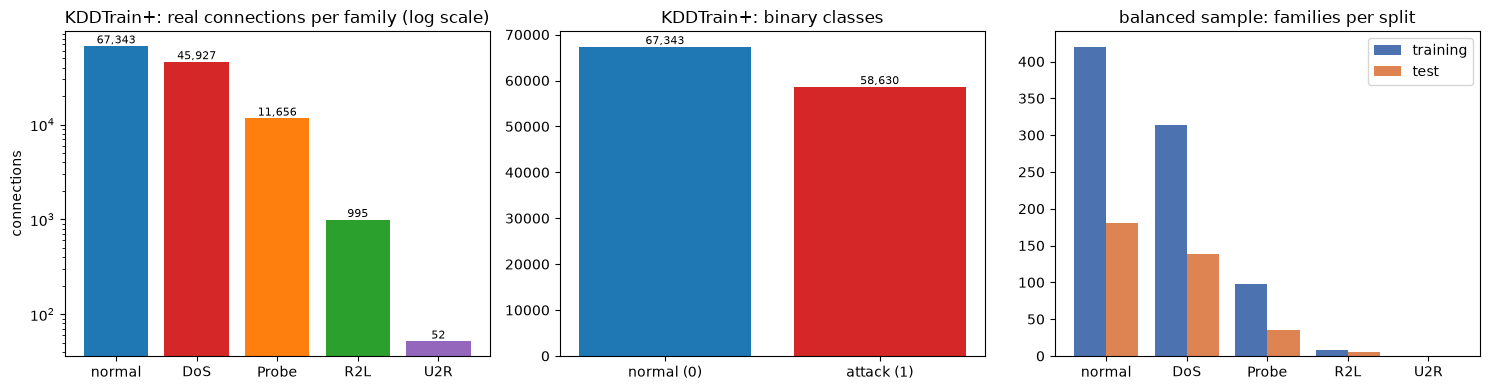

training families: {'normal': 420, 'DoS': 314, 'Probe': 98, 'R2L': 8, 'U2R': 0} | test families: {'normal': 180, 'DoS': 139, 'Probe': 35, 'R2L': 6, 'U2R': 0}


In [7]:
colors = {"normal": "#1f77b4", "DoS": "#d62728", "Probe": "#ff7f0e", "R2L": "#2ca02c", "U2R": "#9467bd"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fc = raw["family"].value_counts().reindex(FAMILIES)
axes[0].bar(FAMILIES, fc.values, color=[colors[f] for f in FAMILIES]); axes[0].set_yscale("log")
axes[0].set_title("KDDTrain+: real connections per family (log scale)"); axes[0].set_ylabel("connections")
for i, v in enumerate(fc.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
bc = raw["is_attack"].value_counts().sort_index()
axes[1].bar(["normal (0)", "attack (1)"], bc.values, color=["#1f77b4", "#d62728"]); axes[1].set_title("KDDTrain+: binary classes")
for i, v in enumerate(bc.values): axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
tr_f = pd.Series(data["fam_train"]).value_counts().reindex(FAMILIES).fillna(0).astype(int)
te_f = pd.Series(data["fam_test"]).value_counts().reindex(FAMILIES).fillna(0).astype(int)
xs = np.arange(len(FAMILIES))
axes[2].bar(xs - 0.2, tr_f.values, 0.4, label="training", color="#4c72b0"); axes[2].bar(xs + 0.2, te_f.values, 0.4, label="test", color="#dd8452")
axes[2].set_xticks(xs); axes[2].set_xticklabels(FAMILIES); axes[2].legend(); axes[2].set_title("balanced sample: families per split")
plt.tight_layout(); plt.show()
print("training families:", tr_f.to_dict(), "| test families:", te_f.to_dict())

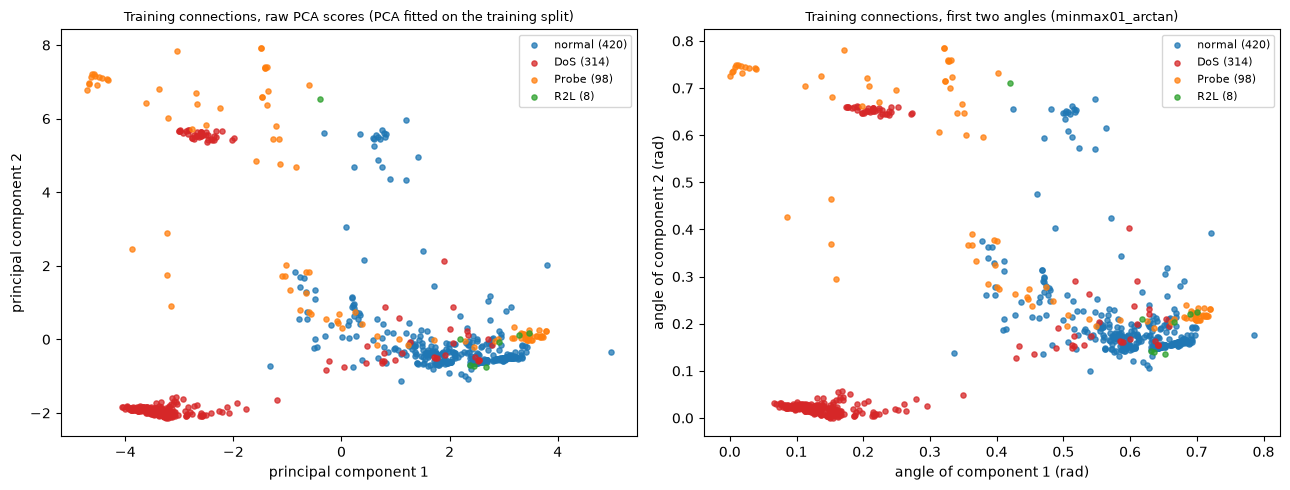

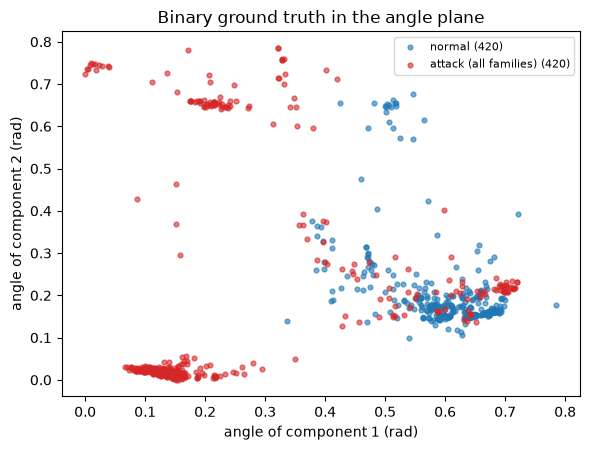

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, key, title, xl in [(axes[0], "P_train", "Training connections, raw PCA scores (PCA fitted on the training split)", "principal component 1"),
                           (axes[1], "A_train", "Training connections, first two angles (%s)" % PRIMARY_VARIANT, "angle of component 1 (rad)")]:
    M = prep[key]
    for f in FAMILIES:                       # draw the common classes first so the rare ones stay visible on top
        m = data["fam_train"] == f
        if m.any():
            ax.scatter(M[m, 0], M[m, 1], s=14, alpha=0.75, c=colors[f], label=f"{f} ({int(m.sum())})")
    ax.set_xlabel(xl); ax.set_ylabel(xl.replace("1", "2")); ax.set_title(title, fontsize=9); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# the same angles seen as attack / normal, which is what the binary model has to separate
fig, ax = plt.subplots(figsize=(6, 4.6))
for cls, name, col in [(0, "normal", "#1f77b4"), (1, "attack (all families)", "#d62728")]:
    m = data["y_train"] == cls
    ax.scatter(prep["A_train"][m, 0], prep["A_train"][m, 1], s=12, alpha=0.6, c=col, label=f"{name} ({int(m.sum())})")
ax.set_xlabel("angle of component 1 (rad)"); ax.set_ylabel("angle of component 2 (rad)")
ax.set_title("Binary ground truth in the angle plane"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Classical baselines on identical inputs

The paper compares its model with "classical ML-based IDS" only in the qualitative bar chart of Fig. 3, whose classical bar
comes from an RNN-LSTM/ANN paper on different data. A comparison that can actually be checked needs the same data and the same
inputs, so the following classical models are trained on **exactly the 4 angles per connection that the quantum circuit
receives**: an RBF-kernel SVM (scikit-learn defaults), a random forest (200 trees), a logistic regression (this is the paper's
classical read-out *without* the quantum circuit, i.e. it shows how much of the result is the linear read-out alone), and a small
MLP (16-8, the "ANN" of the paper's reference [10]). A random forest and an SVM are also trained on all 41 standardised
features to show what the PCA to 4 components costs. No hyper-parameter is tuned for any model, so nobody gets a tuning advantage.
Metrics treat *attack* as the positive class.

In [9]:
def binary_metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0))

def run_baselines(prep, y_tr, y_te, seed):
    models = {  # (model, inputs)
        "SVM rbf (4 angles)":             (SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed), "A"),
        "RandomForest (4 angles)":        (RandomForestClassifier(n_estimators=200, random_state=seed), "A"),
        "LogReg = read-out only (4 angles)": (LogisticRegression(max_iter=2000, random_state=seed), "A"),
        "MLP 16-8 (4 angles)":            (MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=800, random_state=seed), "A"),
        "SVM rbf (all 41 features)":      (SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed), "Z"),
        "RandomForest (all 41 features)": (RandomForestClassifier(n_estimators=200, random_state=seed), "Z"),
    }
    rows, preds = [], {}
    for name, (model, kind) in models.items():
        Xtr, Xte = prep[kind + "_train"], prep[kind + "_test"]
        t0 = time.perf_counter(); model.fit(Xtr, y_tr); t_fit = time.perf_counter() - t0
        pred = model.predict(Xte)
        rows.append(dict(model=name, train_accuracy=accuracy_score(y_tr, model.predict(Xtr)), fit_s=t_fit, **binary_metrics(y_te, pred)))
        preds[name] = pred
    return rows, preds

base_rows, base_preds = run_baselines(prep, data["y_train"], data["y_test"], SEED)
display(pd.DataFrame(base_rows).round(4))

,model,train_accuracy,fit_s,accuracy,precision,recall,f1
0,SVM rbf (4 angles),0.9298,0.0322,0.9250,0.9935,0.8556,0.9194
1,RandomForest (4 angles),1.0000,2.0343,0.9528,0.9766,0.9278,0.9516
2,LogReg = read-out only (4 angles),0.8798,0.0297,0.8889,0.9545,0.8167,0.8802
3,MLP 16-8 (4 angles),0.9214,9.1941,0.9194,0.9689,0.8667,0.9150
4,SVM rbf (all 41 features),0.9726,0.0403,0.9556,0.9881,0.9222,0.9540
5,RandomForest (all 41 features),1.0000,1.2660,0.9806,0.9943,0.9667,0.9803


## Quantum Circuit Architecture

The model of Section III.C-E of the paper, written as one PennyLane QNode on `default.qubit` with 4 wires:

1. **Encoding** $U_{enc}$: $R_Y(\theta_i)$ on qubit $i$, where $\theta_i$ is the normalised PCA score.
2. **Three variational layers.** In every layer each qubit receives trainable $R_X(\phi^x_{l,i})$, $R_Y(\phi^y_{l,i})$,
   $R_Z(\phi^z_{l,i})$ (in this order, as listed in the paper), followed by the entangling block $U_{ent}$.
3. **Measurement:** the expectation value of Pauli-Z on each of the 4 qubits (a vector in $[-1, 1]^4$).
4. **Classical read-out** (outside the circuit): $\hat y = \sigma(w\cdot z + b)$.

Assumptions where the paper is silent: the paper says only "entangling CNOT gates", so $U_{ent}$ is a ring of four CNOTs,
CNOT(0,1), CNOT(1,2), CNOT(2,3), CNOT(3,0), applied after the rotations of every layer. The QNode accepts either one connection
(vector of 4 angles) or a whole mini-batch (matrix, via PennyLane's parameter broadcasting), which is how it is trained; the
drawing below is the same QNode called with one example connection. The cell after the drawing checks that the batched and the
one-by-one evaluation agree. Parameters: $3 \times 4 \times 3 = 36$ circuit angles plus 4 read-out weights plus 1 bias = 41.

0: ──RY(0.60)──RX(4.00)──RY(1.70)──RZ(0.26)─╭●───────╭X──RX(5.39)──RY(0.21)──RZ(4.58)─╭●────── ···
1: ──RY(0.15)──RX(0.10)──RY(5.11)──RZ(5.74)─╰X─╭●────│───RX(1.10)──RY(5.42)──RZ(3.40)─╰X─╭●─── ···
2: ──RY(0.01)──RX(3.81)──RY(4.58)──RZ(3.42)────╰X─╭●─│───RX(1.88)──RY(2.66)──RZ(0.18)────╰X─╭● ···
3: ──RY(0.41)──RX(5.88)──RY(5.13)──RZ(0.02)───────╰X─╰●──RX(0.78)──RY(4.21)──RZ(4.07)───────╰X ···

0: ··· ─╭X──RX(3.87)──RY(2.41)──RZ(6.27)─╭●───────╭X─┤  <Z>
1: ··· ─│───RX(6.16)──RY(4.31)──RZ(4.09)─╰X─╭●────│──┤  <Z>
2: ··· ─│───RX(4.33)──RY(2.44)──RZ(0.85)────╰X─╭●─│──┤  <Z>
3: ··· ─╰●──RX(4.53)──RY(3.30)──RZ(1.95)───────╰X─╰●─┤  <Z>


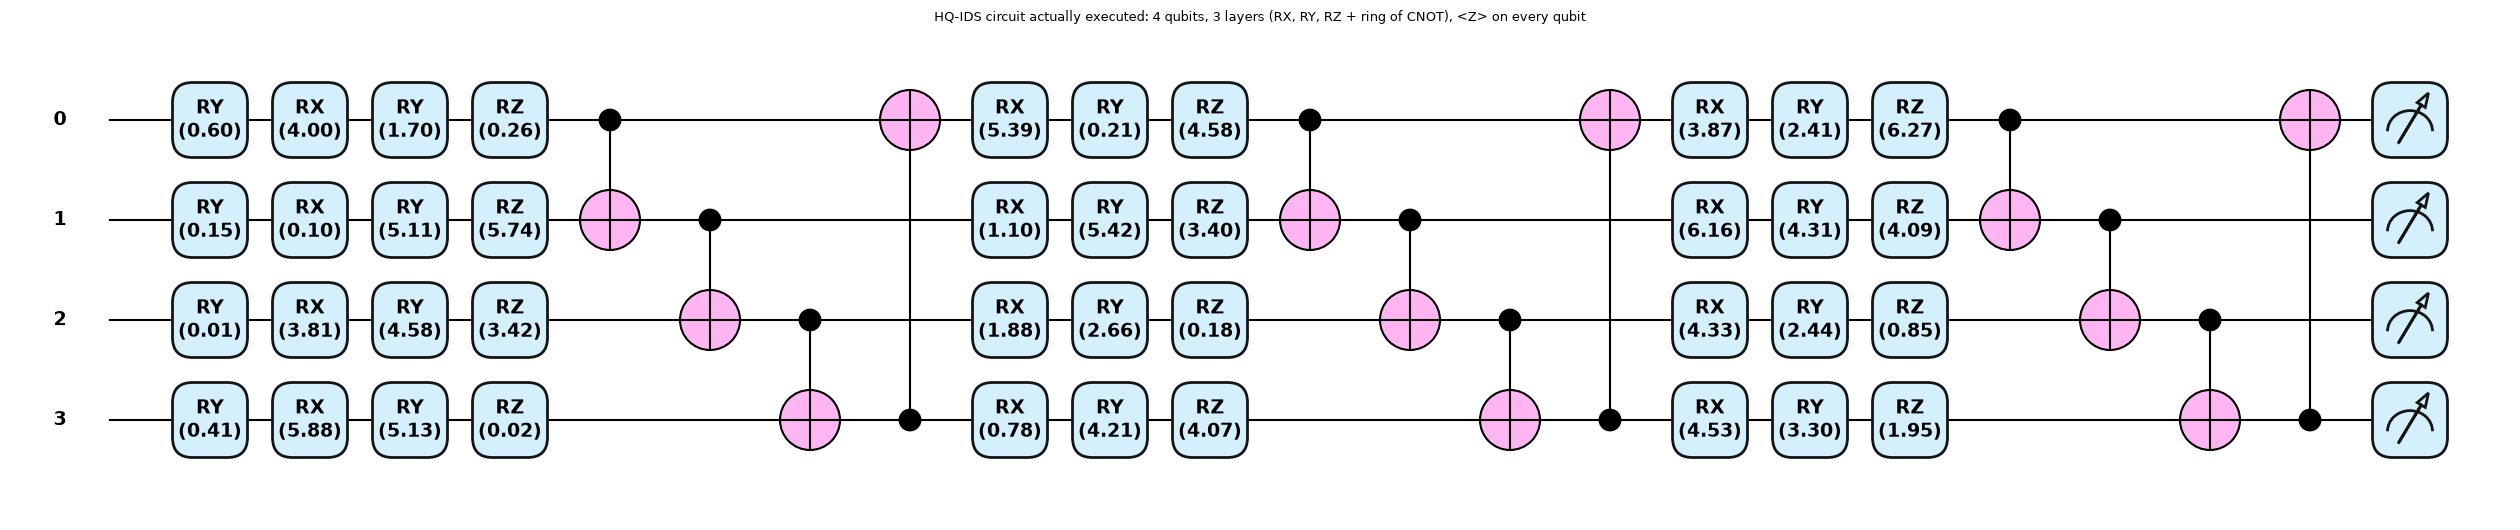

qubits: 4 | depth: 22 | gates: 52 | gate types: {'RY': 16, 'RX': 12, 'RZ': 12, 'CNOT': 12}
trainable parameters: 36 circuit angles + 4 read-out weights + 1 bias = 41


batched and one-by-one <Z> vectors agree (np.allclose); example: [-0.0598 -0.0985  0.02    0.5742]


In [10]:
dev = qml.device("default.qubit", wires=N_QUBITS)

def entangle():
    # CHOICE: ring of CNOTs (the paper only says "entangling CNOT gates")
    for i in range(N_QUBITS):
        qml.CNOT(wires=[i, (i + 1) % N_QUBITS])

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def hqids_circuit(x, weights):
    """x: (4,) or (batch, 4) angles; weights: (N_LAYERS, N_QUBITS, 3) angles for RX, RY, RZ."""
    for i in range(N_QUBITS):
        qml.RY(x[..., i], wires=i)                       # angle encoding, one feature per qubit
    for l in range(N_LAYERS):
        for i in range(N_QUBITS):
            qml.RX(weights[l, i, 0], wires=i)
            qml.RY(weights[l, i, 1], wires=i)
            qml.RZ(weights[l, i, 2], wires=i)
        entangle()
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

demo_w = pnp.array(np.random.default_rng(0).uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS, 3)), requires_grad=False)
x_demo = prep["A_train"][0]
print(qml.draw(hqids_circuit, decimals=2)(x_demo, demo_w))
fig, ax = qml.draw_mpl(hqids_circuit, decimals=2, style="pennylane")(x_demo, demo_w)
fig.suptitle(f"HQ-IDS circuit actually executed: {N_QUBITS} qubits, {N_LAYERS} layers (RX, RY, RZ + ring of CNOT), <Z> on every qubit", fontsize=9, y=1.02)
plt.show()

specs = qml.specs(hqids_circuit)(x_demo, demo_w)["resources"]
n_circ_params = N_LAYERS * N_QUBITS * 3
print("qubits:", len(dev.wires), "| depth:", specs.depth, "| gates:", specs.num_gates, "| gate types:", dict(specs.gate_types))
print(f"trainable parameters: {n_circ_params} circuit angles + {N_QUBITS} read-out weights + 1 bias = {n_circ_params + N_QUBITS + 1}")

# equivalence check: broadcasting over a batch equals one-by-one evaluation of the very same QNode
xb = pnp.array(prep["A_train"][:8], requires_grad=False)
batched = np.stack([np.asarray(o) for o in hqids_circuit(xb, demo_w)], axis=1)
single = np.stack([[float(o) for o in hqids_circuit(pnp.array(xi, requires_grad=False), demo_w)] for xi in prep["A_train"][:8]])
assert np.allclose(batched, single, atol=1e-10)
print("batched and one-by-one <Z> vectors agree (np.allclose); example:", np.round(single[0], 4))

## 4. Training the hybrid model (the paper's algorithm)

The training loop is the algorithm box of the paper, line by line: standardise, PCA, normalise (done above), initialise the
quantum and classical parameters, then for every epoch shuffle the training data, and for every mini-batch of 24 connections
encode, measure, predict $\hat y = \sigma(w\cdot z + b)$, compute the binary cross-entropy and update **all 41 parameters at
once** with Adam (learning rate 0.1) using gradients obtained by automatic differentiation. PennyLane's `default.qubit` is
differentiable end to end by back-propagation (`diff_method="backprop"`), so the same gradient step moves the circuit angles,
the read-out weights and the bias. The binary cross-entropy is evaluated in its numerically stable logits form,
$\max(\ell, 0) - \ell\,y + \log(1 + e^{-|\ell|})$ with $\ell = w\cdot z + b$, which is mathematically the same loss as in the
paper's equation.

After every epoch the notebook records the loss and accuracy of the *current* model on the whole training split (this is the
paper's "training accuracy") and, for the learning curve only, the accuracy on the test split. The test split plays no part in
training, in choosing a model or in stopping: the model after the last epoch is the model that is reported.

In [11]:
def logits(x, weights, w, b):
    z = pnp.stack(hqids_circuit(x, weights), axis=-1)       # (batch, 4) quantum feature vector <Z_i>
    return pnp.dot(z, w) + b                                # classical linear read-out

def bce_loss(x, y, weights, w, b):
    l = logits(x, weights, w, b)
    return pnp.mean(pnp.maximum(l, 0.0) - l * y + pnp.log(1.0 + pnp.exp(-pnp.abs(l))))   # = -mean[y log s(l) + (1-y) log(1-s(l))]

def predict(x, params, chunk=420):
    weights, w, b = params
    out = [np.asarray(logits(pnp.array(x[s:s + chunk], requires_grad=False), weights, w, b)) for s in range(0, len(x), chunk)]
    return np.concatenate(out)

def train_hqids(A_tr, y_tr, A_te, y_te, seed, epochs=EPOCHS, batch=BATCH, lr=LR, verbose=True):
    r = np.random.default_rng(seed); pnp.random.seed(seed)
    # CHOICE: angles uniform on [0, 2pi), read-out weights N(0, 0.1^2), bias 0 (the paper gives no initialisation)
    weights = pnp.array(r.uniform(0, 2 * np.pi, (N_LAYERS, N_QUBITS, 3)), requires_grad=True)
    w = pnp.array(r.normal(0, 0.1, N_QUBITS), requires_grad=True)
    b = pnp.array(0.0, requires_grad=True)
    opt = qml.AdamOptimizer(stepsize=lr)
    hist = []; t_start = time.perf_counter()
    for ep in range(1, epochs + 1):
        perm = r.permutation(len(A_tr))                                  # shuffle the training data every epoch
        for s in range(0, len(perm), batch):
            idx = perm[s:s + batch]
            xb = pnp.array(A_tr[idx], requires_grad=False); yb = pnp.array(y_tr[idx], requires_grad=False)
            weights, w, b = opt.step(lambda wt, ww, bb: bce_loss(xb, yb, wt, ww, bb), weights, w, b)
        l_tr = predict(A_tr, (weights, w, b)); l_te = predict(A_te, (weights, w, b))
        p_tr = 1 / (1 + np.exp(-l_tr))
        hist.append(dict(epoch=ep, train_loss=float(-np.mean(y_tr * np.log(p_tr + 1e-12) + (1 - y_tr) * np.log(1 - p_tr + 1e-12))),
                         train_acc=float(np.mean((l_tr > 0) == y_tr)), test_acc=float(np.mean((l_te > 0) == y_te)),
                         elapsed_s=time.perf_counter() - t_start))
        if verbose and (ep == 1 or ep % 5 == 0 or ep == epochs):
            h = hist[-1]; print(f"epoch {ep:3d}/{epochs} | loss {h['train_loss']:.4f} | train acc {h['train_acc']:.4f} | test acc {h['test_acc']:.4f} | {h['elapsed_s']:.0f} s")
    params = (weights, w, b)
    return params, pd.DataFrame(hist), time.perf_counter() - t_start

t0 = time.time()
params, hist, t_train = train_hqids(prep["A_train"], data["y_train"], prep["A_test"], data["y_test"], SEED)
print(f"training took {t_train/60:.1f} min")

epoch   1/60 | loss 0.4181 | train acc 0.8869 | test acc 0.9028 | 7 s


epoch   5/60 | loss 0.3263 | train acc 0.8524 | test acc 0.8583 | 38 s


epoch  10/60 | loss 0.3381 | train acc 0.8381 | test acc 0.8444 | 84 s


epoch  15/60 | loss 0.2752 | train acc 0.8786 | test acc 0.8889 | 127 s


epoch  20/60 | loss 0.2715 | train acc 0.9083 | test acc 0.9111 | 176 s


...

epoch  40/60 | loss 0.2855 | train acc 0.8869 | test acc 0.8833 | 364 s


epoch  45/60 | loss 0.4257 | train acc 0.8119 | test acc 0.8444 | 399 s


epoch  50/60 | loss 0.2676 | train acc 0.9000 | test acc 0.8861 | 440 s


epoch  55/60 | loss 0.2637 | train acc 0.8976 | test acc 0.9111 | 489 s


epoch  60/60 | loss 0.2906 | train acc 0.8738 | test acc 0.8694 | 526 s
training took 8.8 min


## 5. Metrics, learning curve and confusion matrix (the paper's Fig. 2)

Fig. 2 of the paper shows the training accuracy per epoch and the confusion matrix of the test set. The cell below redraws both
for the primary run (seed 42) and prints the final-epoch metrics, with *attack* as the positive class.

HQ-IDS (seed 42, 60 epochs): train accuracy 0.8738 | test accuracy 0.8694 | precision 0.8556 | recall 0.8889 | F1 0.8719


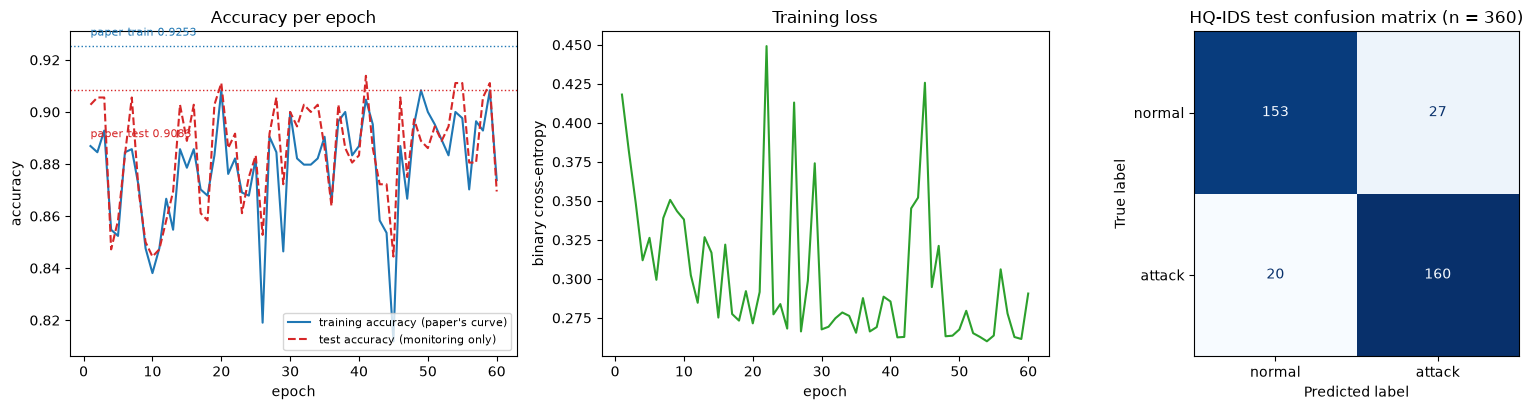

,family,test_connections,predicted_attack,correct,accuracy
0,normal,180,27,153,0.850
1,DoS,139,127,127,0.914
2,Probe,35,32,32,0.914
3,R2L,6,1,1,0.167


In [12]:
l_te = predict(prep["A_test"], params); pred_q = (l_te > 0).astype(int)
l_tr = predict(prep["A_train"], params)
qm = binary_metrics(data["y_test"], pred_q); q_train_acc = accuracy_score(data["y_train"], (l_tr > 0).astype(int))
print(f"HQ-IDS (seed {SEED}, {len(hist)} epochs): train accuracy {q_train_acc:.4f} | test accuracy {qm['accuracy']:.4f} | "
      f"precision {qm['precision']:.4f} | recall {qm['recall']:.4f} | F1 {qm['f1']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(hist["epoch"], hist["train_acc"], label="training accuracy (paper's curve)", color="#1f77b4")
axes[0].plot(hist["epoch"], hist["test_acc"], label="test accuracy (monitoring only)", color="#d62728", ls="--")
axes[0].axhline(0.9253, color="#1f77b4", ls=":", lw=1); axes[0].axhline(0.9083, color="#d62728", ls=":", lw=1)
axes[0].text(1, 0.9253 + 0.004, "paper train 0.9253", color="#1f77b4", fontsize=8); axes[0].text(1, 0.9083 - 0.018, "paper test 0.9083", color="#d62728", fontsize=8)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("accuracy"); axes[0].set_title("Accuracy per epoch"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].plot(hist["epoch"], hist["train_loss"], color="#2ca02c"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("binary cross-entropy"); axes[1].set_title("Training loss")
cm = confusion_matrix(data["y_test"], pred_q, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set_title(f"HQ-IDS test confusion matrix (n = {len(pred_q)})")
plt.tight_layout(); plt.show()

# per-family detection rate: the binary model never saw the family names, but the real labels let us see which attacks it misses
fam_rows = []
for f in FAMILIES:
    m = data["fam_test"] == f
    if m.any():
        fam_rows.append(dict(family=f, test_connections=int(m.sum()), predicted_attack=int(pred_q[m].sum()),
                             correct=int((pred_q[m] == data["y_test"][m]).sum()), accuracy=float((pred_q[m] == data["y_test"][m]).mean())))
display(pd.DataFrame(fam_rows).round(3))

## 6. Seeds, classical comparison and preprocessing ablation

One run on a few hundred test connections is a noisy estimate (the standard error of an accuracy near 0.9 on 360 rows is about
0.016). The cell below repeats the whole pipeline (new balanced draw, new split, new PCA, new initialisation, new training,
all baselines) for every seed in `SEEDS` and reports mean +- standard deviation. In the full run it also trains the primary
architecture under the two alternative readings of the angle normalisation on the first seed, to show how much the unspecified
Min-Max / arctan step matters. Seed 42 of the primary variant is re-used from the cells above.

In [13]:
all_runs = {}     # (variant, seed) -> dict
all_runs[(PRIMARY_VARIANT, SEED)] = dict(prep=prep, data=data, params=params, hist=hist, t_train=t_train, pred=pred_q,
                                         metrics=qm, train_acc=q_train_acc, base_rows=base_rows, base_preds=base_preds)
jobs = [(PRIMARY_VARIANT, s) for s in SEEDS if s != SEED]
if RUN_ABLATION:
    jobs += [(v, SEED) for v in ABLATION_VARIANTS]
for variant, seed in jobs:
    d = draw_sample(seed); p = prepare(d["X_train"], d["X_test"], variant, seed=seed)
    prm, h, tt = train_hqids(p["A_train"], d["y_train"], p["A_test"], d["y_test"], seed, verbose=False)
    lte = predict(p["A_test"], prm); ltr = predict(p["A_train"], prm); pr = (lte > 0).astype(int)
    brows, bpreds = run_baselines(p, d["y_train"], d["y_test"], seed)
    all_runs[(variant, seed)] = dict(prep=p, data=d, params=prm, hist=h, t_train=tt, pred=pr, metrics=binary_metrics(d["y_test"], pr),
                                     train_acc=accuracy_score(d["y_train"], (ltr > 0).astype(int)), base_rows=brows, base_preds=bpreds)
    m = all_runs[(variant, seed)]
    print(f"{variant:16s} seed {seed}: train acc {m['train_acc']:.4f} | test acc {m['metrics']['accuracy']:.4f} | F1 {m['metrics']['f1']:.4f} | {tt/60:.1f} min")

rows = []
for (variant, seed), m in all_runs.items():
    rows.append(dict(variant=variant, seed=seed, train_acc=m["train_acc"], **m["metrics"], train_minutes=m["t_train"] / 60))
runs_df = pd.DataFrame(rows)
display(runs_df.round(4))
primary = runs_df[runs_df["variant"] == PRIMARY_VARIANT]
summary = primary[["train_acc", "accuracy", "precision", "recall", "f1"]].agg(["mean", "std"]).round(4)
print(f"primary variant ({PRIMARY_VARIANT}) over {len(primary)} seed(s):")
display(summary)

minmax01_arctan  seed 43: train acc 0.9167 | test acc 0.9111 | F1 0.9111 | 7.0 min


minmax01_arctan  seed 44: train acc 0.8690 | test acc 0.8861 | F1 0.8912 | 5.5 min


zscore_arctan    seed 42: train acc 0.9131 | test acc 0.9306 | F1 0.9275 | 9.0 min


minmax_pi        seed 42: train acc 0.9214 | test acc 0.9250 | F1 0.9208 | 8.7 min


,variant,seed,train_acc,accuracy,precision,recall,f1,train_minutes
0,minmax01_arctan,42,0.8738,0.8694,0.8556,0.8889,0.8719,8.7700
1,minmax01_arctan,43,0.9167,0.9111,0.9111,0.9111,0.9111,6.9713
2,minmax01_arctan,44,0.8690,0.8861,0.8528,0.9333,0.8912,5.5292
3,zscore_arctan,42,0.9131,0.9306,0.9697,0.8889,0.9275,8.9790
4,minmax_pi,42,0.9214,0.9250,0.9752,0.8722,0.9208,8.6747


primary variant (minmax01_arctan) over 3 seed(s):


,train_acc,accuracy,precision,recall,f1
mean,0.8865,0.8889,0.8732,0.9111,0.8914
std,0.0262,0.0210,0.0329,0.0222,0.0196


## 7. The classical comparison (the idea of the paper's Fig. 3, with numbers)

Test accuracy, F1 and fit time of the quantum model and every classical model on the same inputs, averaged over the seeds of
the primary variant. The paper's Fig. 3 is a qualitative bar chart against a different paper's classical IDS; here the
classical models see the same 4 angles (and, for two of them, all 41 features), so the gap, or the absence of one, is a
statement about the model and not about the data.

,model,test_accuracy,test_accuracy_std,f1,train_accuracy,fit_s
0,"HQ-IDS (quantum, 41 params, 4 angles)",0.8889,0.0171,0.8914,0.8865,425.4102
1,SVM rbf (4 angles),0.9324,0.0105,0.9280,0.9353,0.0277
2,RandomForest (4 angles),0.9648,0.0092,0.9643,1.0000,1.8881
3,LogReg = read-out only (4 angles),0.8870,0.0092,0.8790,0.8722,0.0231
4,MLP 16-8 (4 angles),0.9269,0.0057,0.9236,0.9274,6.8276
5,SVM rbf (all 41 features),0.9694,0.0099,0.9689,0.9750,0.0309
6,RandomForest (all 41 features),0.9870,0.0057,0.9870,1.0000,1.6546


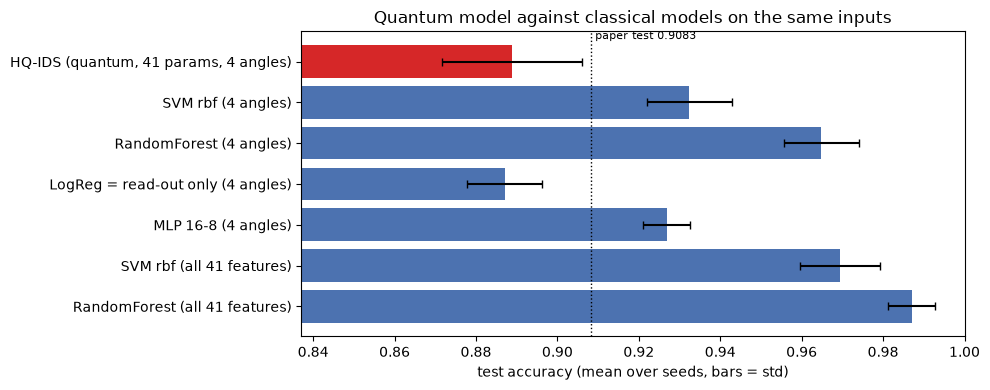

In [14]:
prim_runs = [m for (v, s), m in all_runs.items() if v == PRIMARY_VARIANT]
agg = {}
for m in prim_runs:
    for r_ in m["base_rows"]:
        agg.setdefault(r_["model"], []).append(r_)
comp_rows = [dict(model="HQ-IDS (quantum, 41 params, 4 angles)",
                  test_accuracy=np.mean([m["metrics"]["accuracy"] for m in prim_runs]), test_accuracy_std=np.std([m["metrics"]["accuracy"] for m in prim_runs]),
                  f1=np.mean([m["metrics"]["f1"] for m in prim_runs]), train_accuracy=np.mean([m["train_acc"] for m in prim_runs]),
                  fit_s=np.mean([m["t_train"] for m in prim_runs]))]
for name, lst in agg.items():
    comp_rows.append(dict(model=name, test_accuracy=np.mean([r_["accuracy"] for r_ in lst]), test_accuracy_std=np.std([r_["accuracy"] for r_ in lst]),
                          f1=np.mean([r_["f1"] for r_ in lst]), train_accuracy=np.mean([r_["train_accuracy"] for r_ in lst]),
                          fit_s=np.mean([r_["fit_s"] for r_ in lst])))
comp_df = pd.DataFrame(comp_rows)
display(comp_df.round(4))

fig, ax = plt.subplots(figsize=(10, 4))
cols = ["#d62728"] + ["#4c72b0"] * (len(comp_df) - 1)
ax.barh(comp_df["model"][::-1], comp_df["test_accuracy"][::-1], xerr=comp_df["test_accuracy_std"][::-1], color=cols[::-1], capsize=3)
ax.axvline(0.9083, color="k", ls=":", lw=1); ax.text(0.9083, len(comp_df) - 0.45, " paper test 0.9083", fontsize=8)
lo = max(0.5, comp_df["test_accuracy"].min() - 0.05); ax.set_xlim(lo, 1.0)
ax.set_xlabel("test accuracy (mean over seeds, bars = std)"); ax.set_title("Quantum model against classical models on the same inputs")
plt.tight_layout(); plt.show()

## 8. Noise sweep: is the circuit "NISQ-ready"?

The paper says the model is "scalable to noisy intermediate-scale quantum (NISQ) devices" and, in Fig. 3, shows "enhanced noise
tolerance", but runs only noiseless simulations. To test the idea, the trained circuit (the weights from the cell above are not
changed) is re-evaluated on PennyLane's mixed-state simulator `default.mixed` with a **depolarising channel of probability $p$
after every gate**, on each wire that the gate acts on. This is a coarse noise model (no readout error, no crosstalk, equal
error on one- and two-qubit gates) and is a `# CHOICE:` of this notebook. The mixed-state simulation is slower, so only the
first `N_NOISE_EVAL` test connections are used, with the noiseless accuracy on the same subset as reference. A logistic
regression and an RBF-SVM do not run on quantum hardware, so no classical noise comparison exists; the question answered is
only "how fast does the trained quantum model degrade?".

p = 0.0    accuracy on 120 test connections: 0.9167  (1 s)


p = 0.001  accuracy on 120 test connections: 0.9250  (4 s)


p = 0.003  accuracy on 120 test connections: 0.9167  (6 s)


p = 0.01   accuracy on 120 test connections: 0.5167  (10 s)


p = 0.03   accuracy on 120 test connections: 0.5083  (13 s)
noiseless statevector accuracy on the same subset: 0.9167 | mixed-state p = 0: 0.9167


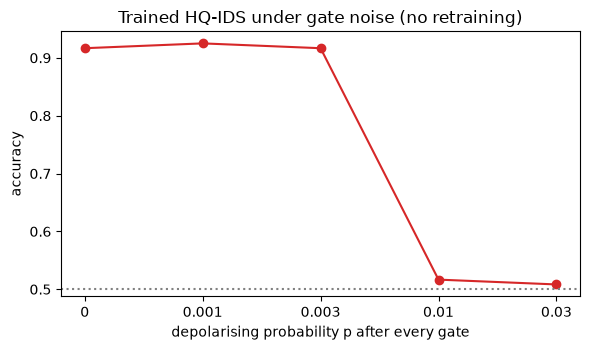

In [15]:
def make_noisy_qnode(p):
    dev_n = qml.device("default.mixed", wires=N_QUBITS)
    @qml.qnode(dev_n, interface="autograd", diff_method="backprop")
    def noisy(x, weights):
        def noise(wires):
            if p > 0:
                for wi in wires: qml.DepolarizingChannel(p, wires=wi)
        for i in range(N_QUBITS):
            qml.RY(x[..., i], wires=i); noise([i])
        for l in range(N_LAYERS):
            for i in range(N_QUBITS):
                qml.RX(weights[l, i, 0], wires=i); noise([i])
                qml.RY(weights[l, i, 1], wires=i); noise([i])
                qml.RZ(weights[l, i, 2], wires=i); noise([i])
            for i in range(N_QUBITS):
                qml.CNOT(wires=[i, (i + 1) % N_QUBITS]); noise([i, (i + 1) % N_QUBITS])
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
    return noisy

weights_t, w_t, b_t = params
Xn = prep["A_test"][:N_NOISE_EVAL]; yn = data["y_test"][:N_NOISE_EVAL]
noise_rows = []
t0 = time.time()
for p in NOISE_LEVELS:
    qn = make_noisy_qnode(p)
    try:
        z = np.stack([np.asarray(o) for o in qn(pnp.array(Xn, requires_grad=False), weights_t)], axis=1)      # parameter broadcasting
    except Exception as e:
        z = np.stack([[float(o) for o in qn(pnp.array(xi, requires_grad=False), weights_t)] for xi in Xn])      # one by one
    lg = z @ np.asarray(w_t) + float(b_t)
    noise_rows.append(dict(depolarising_p=p, test_accuracy=float(np.mean((lg > 0) == yn)), mean_abs_z=float(np.abs(z).mean())))
    print(f"p = {p:<6} accuracy on {len(yn)} test connections: {noise_rows[-1]['test_accuracy']:.4f}  ({time.time()-t0:.0f} s)")
noise_df = pd.DataFrame(noise_rows)
ref = noise_df.loc[noise_df["depolarising_p"] == 0, "test_accuracy"].iloc[0]
# sanity: the p = 0 mixed-state run equals the statevector run on the same subset
sv_acc = float(np.mean((predict(Xn, params) > 0) == yn))
print("noiseless statevector accuracy on the same subset:", round(sv_acc, 4), "| mixed-state p = 0:", round(ref, 4))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(range(len(noise_df)), noise_df["test_accuracy"], "o-", color="#d62728"); ax.set_xticks(range(len(noise_df)))
ax.set_xticklabels([f"{p:g}" for p in noise_df["depolarising_p"]]); ax.axhline(0.5, color="gray", ls=":")
ax.set_xlabel("depolarising probability p after every gate"); ax.set_ylabel("accuracy"); ax.set_title("Trained HQ-IDS under gate noise (no retraining)")
plt.tight_layout(); plt.show()

## 9. Paper versus this notebook

Each row is one claim of the paper. The verdict is **reproduced** when our value is within 0.02 of the paper's (two accuracy
points), **exceeded** when it is more than 0.02 above, **not reached** when more than 0.02 below. Our values are the mean over
the seeds of the primary variant. The qualitative claims get their own tests, stated in the "check" column. Remember that the
paper's data are synthetic and unpublished, so even a "reproduced" number is only a statement about NSL-KDD with the same model
and recipe.

In [16]:
mean_train = float(np.mean([m["train_acc"] for m in prim_runs])); mean_test = float(np.mean([m["metrics"]["accuracy"] for m in prim_runs]))
std_test = float(np.std([m["metrics"]["accuracy"] for m in prim_runs]))
TOL = 0.02
def verdict(paper, ours, tol=TOL):
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")

claims = []
claims.append(dict(claim="Training accuracy after the last epoch = 0.9253", check=f"mean over {len(prim_runs)} seed(s), epochs = {EPOCHS}",
                   paper=0.9253, notebook=round(mean_train, 4), verdict=verdict(0.9253, mean_train) + ("" if EPOCHS == EPOCHS_PAPER else f" (only {EPOCHS} of 60 epochs in FAST_MODE)")))
claims.append(dict(claim="Test accuracy = 0.9083", check=f"mean over {len(prim_runs)} seed(s) (std {std_test:.4f})",
                   paper=0.9083, notebook=round(mean_test, 4), verdict=verdict(0.9083, mean_test) + ("" if EPOCHS == EPOCHS_PAPER else f" (only {EPOCHS} of 60 epochs in FAST_MODE)")))
gap = mean_train - mean_test
claims.append(dict(claim="Generalises to unseen data (paper train - test gap = 0.017)", check="train - test accuracy gap (generalises if gap <= 0.03)",
                   paper=0.017, notebook=round(gap, 4), verdict="reproduced" if gap <= 0.03 else "not reached (overfits)"))
h0 = all_runs[(PRIMARY_VARIANT, SEED)]["hist"]
e5 = min(5, len(h0)); fast_ok = (h0["train_acc"].iloc[e5 - 1] - h0["train_acc"].iloc[0]) >= 0 and (h0["train_acc"].iloc[-1] - h0["train_acc"].iloc[e5 - 1]) <= 0.05
claims.append(dict(claim="Training accuracy rises quickly in the first epochs, then converges (steady)", check="within 5 points of the final value by epoch 5 and the last 5 epochs move by <= 0.02",
                   paper="qualitative", notebook=f"epoch1 {h0['train_acc'].iloc[0]:.3f}, epoch{e5} {h0['train_acc'].iloc[e5-1]:.3f}, last {h0['train_acc'].iloc[-1]:.3f}",
                   verdict="reproduced" if (h0["train_acc"].iloc[-1] - h0["train_acc"].iloc[e5 - 1] <= 0.05 and abs(h0["train_acc"].iloc[-1] - h0["train_acc"].iloc[-min(5, len(h0))]) <= 0.02) else "not reproduced"))
cm_ = confusion_matrix(data["y_test"], pred_q, labels=[0, 1])
claims.append(dict(claim="Confusion matrix: most normal and attack connections correct, few misclassified", check="every class recall >= 0.8 (seed 42)",
                   paper="qualitative", notebook=f"normal recall {cm_[0,0]/cm_[0].sum():.3f}, attack recall {cm_[1,1]/cm_[1].sum():.3f}",
                   verdict="reproduced" if min(cm_[0, 0] / cm_[0].sum(), cm_[1, 1] / cm_[1].sum()) >= 0.8 else "not reached"))
best_cls = comp_df.iloc[1:][comp_df.iloc[1:]["model"].str.contains("4 angles")].sort_values("test_accuracy", ascending=False).iloc[0]
d_ = mean_test - float(best_cls["test_accuracy"])
claims.append(dict(claim="Competitive with classical ML IDS (better accuracy than classical)", check="HQ-IDS minus best classical model on the same 4 angles (competitive if >= -0.02; better if > 0.02)",
                   paper="qualitative", notebook=f"{d_:+.4f} vs {best_cls['model']} ({best_cls['test_accuracy']:.4f})",
                   verdict="better than classical" if d_ > 0.02 else ("competitive (within 2 points)" if d_ >= -0.02 else "not competitive (classical clearly better)")))
lr_ = comp_df[comp_df["model"].str.startswith("LogReg")].iloc[0]
d2 = mean_test - float(lr_["test_accuracy"])
claims.append(dict(claim="The quantum circuit adds representational power (feature extraction) over a linear read-out", check="HQ-IDS minus logistic regression on the same 4 angles",
                   paper="implied", notebook=f"{d2:+.4f}", verdict="supported (circuit helps by > 2 points)" if d2 > 0.02 else ("not supported (no gain over a linear read-out)" if d2 <= 0.02 else "")))
n_lo = noise_df.iloc[1]["test_accuracy"]; n_hi = noise_df.iloc[-1]["test_accuracy"]
claims.append(dict(claim="NISQ-ready / enhanced noise tolerance (Fig. 3)", check="accuracy kept at p = 0.1 % and p = 3 % per gate (the paper gives no numbers, so only our own degradation curve can be reported)",
                   paper="qualitative", notebook=f"p=0: {ref:.3f}, p={noise_df.iloc[1]['depolarising_p']:g}: {n_lo:.3f}, p={noise_df.iloc[-1]['depolarising_p']:g}: {n_hi:.3f}",
                   verdict="cannot be checked against the paper (no classical noise comparison possible); degradation curve shown"))
claims.append(dict(claim="Scalability equal to classical IDS (Fig. 3)", check="only 4 qubits simulated, no scaling experiment in the paper", paper="qualitative", notebook="-", verdict="cannot be checked"))
comparison = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 120)
display(comparison)
print(comparison["verdict"].str.split(" ").str[0].value_counts().to_dict())
if len(runs_df[runs_df["variant"] != PRIMARY_VARIANT]):
    print("\nAblation of the unspecified angle normalisation (seed %d):" % SEED)
    display(runs_df[runs_df["seed"] == SEED][["variant", "train_acc", "accuracy", "f1"]].round(4))

,claim,check,paper,notebook,verdict
0,Training accuracy after the last epoch = 0.9253,"mean over 3 seed(s), epochs = 60",0.9253,0.8865,not reached
1,Test accuracy = 0.9083,mean over 3 seed(s) (std 0.0171),0.9083,0.8889,reproduced
2,Generalises to unseen data (paper train - test gap = 0.017),train - test accuracy gap (generalises if gap <= 0.03),0.017,-0.0024,reproduced
3,"Training accuracy rises quickly in the first epochs, then converges (steady)",within 5 points of the final value by epoch 5 and the last 5 epochs move by <= 0.02,qualitative,"epoch1 0.887, epoch5 0.852, last 0.874",reproduced
4,"Confusion matrix: most normal and attack connections correct, few misclassified",every class recall >= 0.8 (seed 42),qualitative,"normal recall 0.850, attack recall 0.889",reproduced
5,Competitive with classical ML IDS (better accuracy than classical),HQ-IDS minus best classical model on the same 4 angles (competitive if >= -0.02; better if > 0.02),qualitative,-0.0759 vs RandomForest (4 angles) (0.9648),not competitive (classical clearly better)
6,The quantum circuit adds representational power (feature extraction) over a linear read-out,HQ-IDS minus logistic regression on the same 4 angles,implied,+0.0019,not supported (no gain over a linear read-out)
7,NISQ-ready / enhanced noise tolerance (Fig. 3),"accuracy kept at p = 0.1 % and p = 3 % per gate (the paper gives no numbers, so only our own degradation curve can b...",qualitative,"p=0: 0.917, p=0.001: 0.925, p=0.03: 0.508",cannot be checked against the paper (no classical noise comparison possible); degradation curve shown
8,Scalability equal to classical IDS (Fig. 3),"only 4 qubits simulated, no scaling experiment in the paper",qualitative,-,cannot be checked


{'reproduced': 4, 'not': 3, 'cannot': 2}

Ablation of the unspecified angle normalisation (seed 42):


,variant,train_acc,accuracy,f1
0,minmax01_arctan,0.8738,0.8694,0.8719
3,zscore_arctan,0.9131,0.9306,0.9275
4,minmax_pi,0.9214,0.9250,0.9208


## Reading the paper critically

**The data are synthetic and unpublished.** Everything the paper reports (92.53 % train, 90.83 % test) refers to a "generated
network traffic data set" whose generator, size, class balance and difficulty are not stated. A synthetic set can be made as
easy or as hard as the author likes, so the numbers say nothing about real intrusion detection and cannot be compared with
published results on CIC-IDS2017 or NSL-KDD. This notebook can only check whether the *recipe* (4 qubits, 3 layers, Adam 0.1,
60 epochs, batch 24) produces accuracies of that order on a real dataset of the same kind.

**No baseline is run in the paper.** Fig. 3 compares the quantum model with "classical ML-based IDS" through a bar chart on
accuracy, scalability, feature representation, noise tolerance and model complexity, but the values are not given, no classical
model was trained on the synthetic data, and the classical reference ([10]) is a different paper's RNN-LSTM versus ANN study of
R2L attacks. The claim of "enhanced noise tolerance" is not backed by any noisy simulation in the text. Section 7 and 8 here run
what the paper did not: classical models on identical inputs, and a depolarising-noise sweep.

**The quantum part may be doing little.** The pipeline compresses 41 features into 4 numbers with PCA before any quantum gate acts,
and the read-out is a logistic regression. The logistic regression on the same 4 angles (Section 7) shows what the read-out
alone achieves; if the circuit does not beat it, the "quantum feature extraction" is not what produces the accuracy. A fair claim
of quantum benefit would need an ablation with the circuit removed, which the paper does not report.

**Under-specified details change the result.** The order and ranges of "Min-Max scaling and arctangent normalisation", the CNOT
topology, the parameter initialisation, the sample size and the split are all missing. The ablation in Section 6 shows that
the angle normalisation alone can move the accuracy by several points: with Min-Max to $[0, 1]$ followed by arctan the angles
only occupy $[0, \pi/4]$, i.e. a quarter of the rotation range that an $R_Y$ encoding could use.

**Statistics.** One run on one unspecified split, no seeds, no intervals. On a test set of a few hundred connections a
difference of one or two accuracy points is within noise. "Training accuracy" is also not defined (final epoch, best epoch or a
running mini-batch average), and no validation split is mentioned, so epoch count and learning rate may have been chosen with
the test set.

**Scale.** Four qubits and a 41-parameter model are trivially simulable (the whole training takes minutes on a CPU), which is
consistent with the claim that nothing here needs a quantum computer, and no scaling experiment backs the statement that the
architecture "scales" to larger devices or data.

## Exercises

1. **Angle range.** Set `PRIMARY_VARIANT = "minmax_pi"` (angles in $[0, \pi]$, no arctan) and rerun. How do the learning curve,
   the final accuracy and the gap to the logistic regression change? Why can a larger angle range help an $R_Y$ encoding?
2. **Circuit removal.** The logistic regression on the 4 angles is the read-out without the circuit. Replace the circuit by
   the identity (return $\cos\theta_i$, the exact $\langle Z_i\rangle$ after encoding with no variational layers) and train
   only the 5 classical parameters. How much of the accuracy is due to the 36 variational angles?
3. **Entanglement.** Change `entangle()` to a linear chain without the closing CNOT(3,0), or remove it altogether. Does the
   test accuracy move by more than the seed-to-seed spread of Section 6?
4. **Depth and width.** Try `N_LAYERS = 1, 2, 6` and `N_QUBITS = 2, 6, 8` (the PCA follows the qubit count). Plot accuracy
   against the number of trainable parameters and compare with the MLP of Section 3.
5. **Shots and noise.** Replace the exact expectation values by a finite-shot estimate (`qml.device("default.qubit", wires=4,
   shots=1000)` with `diff_method="parameter-shift"`) and compare training time and accuracy. Then combine shot noise with the
   depolarising sweep of Section 8: at which noise level does the model fall below the logistic regression?